In [ ]:
%pip install transformers -q


In [ ]:
!python -V

In [ ]:
import gc
import json
import os
from collections import OrderedDict
import numpy as np
import pandas as pd
from pathlib import Path
from dataclasses import dataclass, field
from typing import Optional

import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display
from torch.utils.data import Dataset, DataLoader
from transformers import AutoImageProcessor, AutoModel
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
from tqdm.auto import tqdm


In [ ]:
%ls -l /kaggle/input/datasets/yanplayz08/coco-subset-for-pose-estimation/dataset/annotations_trainval2017/

## Self-Supervised Features (DINOv2 + MLP)

Pipeline:
1. Crop person images using GT bounding boxes
2. Extract frozen DINOv2 CLS features (cached to disk)
3. Train a lightweight MLP to regress 17 normalized COCO keypoints
4. Evaluate with COCOeval and compare against Approaches A and B


In [ ]:
_DATA = Path('/kaggle/input/datasets/yanplayz08/coco-subset-for-pose-estimation/dataset')
_ANNS = _DATA / 'annotations_trainval2017'

@dataclass
class Config:
    # Data
    data_dir:     Path = _DATA
    train_images: Path = _DATA / 'train'
    val_images:   Path = _DATA / 'val'
    train_json:   Path = _ANNS / 'person_keypoints_train2017.json'
    val_json:     Path = _ANNS / 'person_keypoints_val2017.json'

    # Output — shared metrics file so ablation table includes Approaches A & B
    metrics_path:    Path = Path('/kaggle/working/metrics.json')
    predictions_dir: Path = Path('/kaggle/working/predictions')
    cache_dir:       Path = Path('/kaggle/working/ssl_cache')

    # DINOv2 backbone (frozen)
    backbone:    str = 'facebook/dinov2-base'
    feature_dim: int = 768    # DINOv2-base CLS token size
    crop_size:   int = 224    # ViT input resolution
    crop_pad:    float = 0.1  # fractional padding around GT bbox

    # MLP head
    mlp_hidden:   tuple = (512, 256)
    num_keypoints: int = 17

    # Training
    max_train_anns: Optional[int] = None  # None = full dataset
    batch_size:     int = 128
    extract_batch:  int = 64
    num_workers:    int = min(8, os.cpu_count() or 2)
    prefetch_factor: int = 4
    pin_memory:     bool = True
    persistent_workers: bool = True
    use_amp:        bool = True
    image_cache_size: int = 128
    lr:             float = 2e-4
    weight_decay:   float = 1e-4
    epochs:         int = 50

    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'

cfg = Config()
print(f"Device: {cfg.device}, Backbone: {cfg.backbone}")
print(cfg.num_workers)

In [ ]:
coco_train = COCO(cfg.train_json)
coco_val   = COCO(cfg.val_json)

train_ann_ids = coco_train.getAnnIds(catIds=[1], iscrowd=False)
val_ann_ids   = coco_val.getAnnIds(catIds=[1], iscrowd=False)
train_anns = [a for a in coco_train.loadAnns(train_ann_ids) if a['num_keypoints'] > 0]
val_anns   = [a for a in coco_val.loadAnns(val_ann_ids)   if a['num_keypoints'] > 0]

print(f"Train annotations with keypoints: {len(train_anns):,}")
print(f"Val   annotations with keypoints: {len(val_anns):,}")
print(f"Training cap (max_train_anns):    {cfg.max_train_anns:,}" if cfg.max_train_anns else "Training cap (max_train_anns):    None (full dataset)")
del coco_train, coco_val


## Dataset


In [ ]:
class PersonCropDataset(Dataset):
    """One sample = one GT person annotation -> padded crop + keypoints normalized to that crop."""

    def __init__(self, image_dir: Path, json_file: Path,
                 crop_size: int = 224, crop_pad: float = 0.1,
                 max_anns: Optional[int] = None):
        self.image_dir = Path(image_dir)
        self.crop_size = crop_size
        self.pad       = crop_pad
        self.image_cache_size = cfg.image_cache_size if 'cfg' in globals() else 128
        self._image_cache = OrderedDict()

        coco = COCO(json_file)
        ann_ids = coco.getAnnIds(catIds=[1], iscrowd=False)
        anns = [a for a in coco.loadAnns(ann_ids) if a['num_keypoints'] > 0]
        if max_anns:
            anns = anns[:max_anns]

        self.anns      = anns
        self.img_index = {img['id']: img for img in coco.loadImgs(coco.getImgIds())}

    def __len__(self):
        return len(self.anns)

    def _pad_crop(self, img: np.ndarray, bbox: list):
        """Return (crop, x1, y1, crop_w, crop_h) with fractional padding."""
        x, y, w, h = bbox
        ih, iw = img.shape[:2]
        x1 = max(0, int(x - self.pad * w));   y1 = max(0, int(y - self.pad * h))
        x2 = min(iw, int(x + (1 + self.pad) * w)); y2 = min(ih, int(y + (1 + self.pad) * h))
        crop = img[y1:y2, x1:x2]
        if crop.size == 0:
            x1, y1, x2, y2 = 0, 0, iw, ih
            crop = img
        return crop, x1, y1, (x2 - x1), (y2 - y1)

    def _load_image(self, img_info: dict) -> np.ndarray:
        file_name = img_info['file_name']
        cached = self._image_cache.get(file_name)
        if cached is not None:
            self._image_cache.move_to_end(file_name)
            return cached

        img = cv2.imread(str(self.image_dir / file_name))
        if img is None:
            img = np.zeros((img_info['height'], img_info['width'], 3), dtype=np.uint8)
        else:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        self._image_cache[file_name] = img
        if len(self._image_cache) > self.image_cache_size:
            self._image_cache.popitem(last=False)
        return img

    def __getitem__(self, idx):
        ann      = self.anns[idx]
        img_info = self.img_index[ann['image_id']]
        img      = self._load_image(img_info)

        crop, cx, cy, cw, ch = self._pad_crop(img, ann['bbox'])
        crop = cv2.resize(crop, (self.crop_size, self.crop_size))

        kpts = np.array(ann['keypoints'], dtype=np.float32).reshape(-1, 3)
        kpts_norm      = kpts[:, :2].copy()
        kpts_norm[:, 0] = (kpts_norm[:, 0] - cx) / max(cw, 1)
        kpts_norm[:, 1] = (kpts_norm[:, 1] - cy) / max(ch, 1)

        return {
            'crop':      crop,                              # (H, W, 3) uint8
            'kpts_norm': kpts_norm.astype(np.float32),     # (17, 2) in [0, 1] crop space
            'vis':       kpts[:, 2].astype(np.float32),    # (17,)
            'image_id':  ann['image_id'],
            'bbox':      ann['bbox'],
            'crop_meta': [cx, cy, cw, ch],
        }


class FeatureDataset(Dataset):
    """Thin wrapper around cached DINOv2 features for fast MLP training."""

    def __init__(self, feats: np.ndarray, kpts: np.ndarray, vis: np.ndarray):
        self.f = torch.from_numpy(feats).float()
        self.k = torch.from_numpy(kpts).float()
        self.v = torch.from_numpy(vis).float()

    def __len__(self):
        return len(self.f)

    def __getitem__(self, i):
        return self.f[i], self.k[i], self.v[i]


def _collate(batch):
    return {
        'crop':      [b['crop'] for b in batch],
        'kpts_norm': np.stack([b['kpts_norm'] for b in batch]),
        'vis':       np.stack([b['vis']       for b in batch]),
        'image_id':  [b['image_id']  for b in batch],
        'bbox':      [b['bbox']      for b in batch],
        'crop_meta': [b['crop_meta'] for b in batch],
    }


In [ ]:
class MetricLogger:
    def __init__(self, metrics_path: Path):
        self.metrics_path = Path(metrics_path)
        if self.metrics_path.exists():
            with open(self.metrics_path) as f:
                try:
                    self.history = json.load(f)
                    print(f"Resumed: {len(self.history)} experiments in {self.metrics_path.name}")
                except json.JSONDecodeError:
                    self.history = {}
        else:
            self.history = {}

    def reset(self):
        self.history = {}
        with open(self.metrics_path, 'w') as f:
            json.dump(self.history, f, indent=2)
        print(f"Reset metrics in {self.metrics_path.name}")

    def log(self, name: str, metrics: dict):
        self.history[name] = metrics
        with open(self.metrics_path, 'w') as f:
            json.dump(self.history, f, indent=2)
        print(f"Logged: {name}")

    def get_ablation_table(self) -> pd.DataFrame:
        return pd.DataFrame.from_dict(self.history, orient='index') if self.history else pd.DataFrame()


## Backbone & Feature Extraction


In [ ]:
# delete cfg.cache_dir
# !rm -rf {cfg.cache_dir}

In [50]:
def extract_and_cache(dataset: PersonCropDataset, processor, backbone,
                      cfg: Config, split: str):
    """
    Extract DINOv2 CLS features for all person crops and cache to disk.
    On subsequent calls the cache is loaded instantly without re-running the backbone.

    Returns: (features, kpts_norm, vis, meta_list)
    """
    cache = cfg.cache_dir
    feat_f = cache / f'{split}_feats.npy'
    kpt_f  = cache / f'{split}_kpts.npy'
    vis_f  = cache / f'{split}_vis.npy'
    meta_f = cache / f'{split}_meta.json'

    if all(f.exists() for f in [feat_f, kpt_f, vis_f, meta_f]):
        print(f"[{split}] Loading cached features ({len(dataset):,} samples)...")
        return (np.load(feat_f), np.load(kpt_f),
                np.load(vis_f), json.loads(meta_f.read_text()))

    cache.mkdir(parents=True, exist_ok=True)
    loader_kwargs = dict(
        batch_size=cfg.extract_batch,
        num_workers=cfg.num_workers,
        collate_fn=_collate,
        shuffle=False,
        pin_memory=cfg.pin_memory,
    )
    if cfg.num_workers > 0:
        loader_kwargs['persistent_workers'] = cfg.persistent_workers
        loader_kwargs['prefetch_factor'] = cfg.prefetch_factor
    loader = DataLoader(dataset, **loader_kwargs)

    feats_l, kpts_l, vis_l, meta = [], [], [], []
    backbone.eval()
    amp_enabled = cfg.use_amp and str(cfg.device).startswith('cuda')
    with torch.inference_mode():
        for batch in tqdm(loader, desc=f"Extracting [{split}]"):
            inputs = processor(images=batch['crop'], return_tensors='pt')
            inputs = {k: v.to(cfg.device, non_blocking=cfg.pin_memory) for k, v in inputs.items()}
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=amp_enabled):
                out = backbone(**inputs)
            feats_l.append(out.last_hidden_state[:, 0].float().cpu().numpy())  # CLS token
            kpts_l.append(batch['kpts_norm'])
            vis_l.append(batch['vis'])
            for img_id, bbox, crop_meta in zip(
                    batch['image_id'], batch['bbox'], batch['crop_meta']):
                meta.append({'image_id': int(img_id),
                             'bbox': list(bbox), 'crop_meta': list(crop_meta)})

    feats = np.concatenate(feats_l)
    kpts  = np.concatenate(kpts_l)
    vis   = np.concatenate(vis_l)

    np.save(feat_f, feats); np.save(kpt_f, kpts); np.save(vis_f, vis)
    meta_f.write_text(json.dumps(meta))
    print(f"[{split}] Cached {len(feats):,} feature vectors -> {cache}")
    return feats, kpts, vis, meta


In [51]:
print(f"Loading DINOv2 backbone: {cfg.backbone}")
processor = AutoImageProcessor.from_pretrained(cfg.backbone)
backbone  = AutoModel.from_pretrained(cfg.backbone).to(cfg.device)
backbone.eval()
print(f"Parameters: {sum(p.numel() for p in backbone.parameters()):,}")
print(f"CLS feature dim: {backbone.config.hidden_size}")


Loading DINOv2 backbone: facebook/dinov2-base


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Parameters: 86,580,480
CLS feature dim: 768


In [52]:
train_ds = PersonCropDataset(cfg.train_images, cfg.train_json,
                             cfg.crop_size, cfg.crop_pad, cfg.max_train_anns)
val_ds   = PersonCropDataset(cfg.val_images,   cfg.val_json,
                             cfg.crop_size, cfg.crop_pad)

train_feats, train_kpts, train_vis, train_meta = \
    extract_and_cache(train_ds, processor, backbone, cfg, 'train')
val_feats, val_kpts, val_vis, val_meta = \
    extract_and_cache(val_ds,   processor, backbone, cfg, 'val')

# Release backbone — features are now on disk, GPU is free for MLP training
del backbone, processor
gc.collect()
if cfg.device == 'cuda':
    torch.cuda.empty_cache()
print("Backbone released.")
print(f"Train features: {train_feats.shape}  Val features: {val_feats.shape}")


loading annotations into memory...
Done (t=7.14s)
creating index...
index created!
loading annotations into memory...
Done (t=0.29s)
creating index...
index created!


Extracting [train]:   0%|          | 0/2341 [00:00<?, ?it/s]

[train] Cached 149,813 feature vectors -> /kaggle/working/ssl_cache


Extracting [val]:   0%|          | 0/100 [00:00<?, ?it/s]

[val] Cached 6,352 feature vectors -> /kaggle/working/ssl_cache
Backbone released.
Train features: (149813, 768)  Val features: (6352, 768)


## MLP Keypoint Regressor


In [53]:
class KeypointMLP(nn.Module):
    """
    MLP that maps a DINOv2 CLS token to 17 keypoint (x, y) predictions,
    normalized to [0, 1] in the person-crop coordinate space.

    Architecture: Linear -> LayerNorm -> GELU -> Dropout  (repeated per hidden layer)
    Final sigmoid ensures outputs stay in [0, 1].
    """

    def __init__(self, input_dim: int, hidden: tuple, num_kpts: int = 17):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.GELU(), nn.Dropout(0.1)]
            prev = h
        layers.append(nn.Linear(prev, num_kpts * 2))
        self.net     = nn.Sequential(*layers)
        self.num_kpts = num_kpts

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.sigmoid(self.net(x)).reshape(-1, self.num_kpts, 2)


def keypoint_loss(pred: torch.Tensor, gt: torch.Tensor, vis: torch.Tensor) -> torch.Tensor:
    """Smooth L1 on visible keypoints only. Returns 0 if no visible keypoints in batch."""
    mask = vis > 0  # (B, 17)
    if not mask.any():
        return pred.sum() * 0.0
    return F.smooth_l1_loss(pred[mask], gt[mask])


In [54]:
def train_mlp(cfg: Config, train_feats: np.ndarray,
              train_kpts: np.ndarray, train_vis: np.ndarray):
    loader = DataLoader(
        FeatureDataset(train_feats, train_kpts, train_vis),
        batch_size=cfg.batch_size, shuffle=True, num_workers=0, pin_memory=True,
    )

    model     = KeypointMLP(cfg.feature_dim, cfg.mlp_hidden, cfg.num_keypoints).to(cfg.device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, cfg.epochs)

    history = []
    for epoch in range(1, cfg.epochs + 1):
        model.train()
        total = 0.0
        for feats, kpts, vis in loader:
            feats = feats.to(cfg.device)
            kpts  = kpts.to(cfg.device)
            vis   = vis.to(cfg.device)
            loss  = keypoint_loss(model(feats), kpts, vis)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item()
        scheduler.step()
        avg = total / len(loader)
        history.append(avg)
        if epoch % 5 == 0 or epoch == 1:
            print(f"Epoch {epoch:3d}/{cfg.epochs}  loss={avg:.6f}  lr={scheduler.get_last_lr()[0]:.2e}")

    return model, history


def predict_coco(model: KeypointMLP, val_feats: np.ndarray,
                 val_meta: list, cfg: Config) -> list:
    """
    Run the trained MLP on val features and produce COCO-format predictions.
    Denormalizes keypoints from crop space back to original image coordinates.
    """
    dummy_kpts = np.zeros((len(val_feats), cfg.num_keypoints, 2), dtype=np.float32)
    dummy_vis  = np.zeros((len(val_feats), cfg.num_keypoints), dtype=np.float32)
    loader = DataLoader(FeatureDataset(val_feats, dummy_kpts, dummy_vis),
                        batch_size=cfg.batch_size, shuffle=False)

    all_preds_norm = []
    model.eval()
    with torch.no_grad():
        for feats, _, _ in loader:
            all_preds_norm.append(model(feats.to(cfg.device)).cpu().numpy())
    all_preds_norm = np.concatenate(all_preds_norm)  # (N, 17, 2)

    predictions = []
    for pred_norm, meta in zip(all_preds_norm, val_meta):
        cx, cy, cw, ch = meta['crop_meta']
        kpt = np.ones((cfg.num_keypoints, 3), dtype=np.float32)
        kpt[:, 0] = pred_norm[:, 0] * cw + cx   # x in image coords
        kpt[:, 1] = pred_norm[:, 1] * ch + cy   # y in image coords
        predictions.append({
            'image_id':    meta['image_id'],
            'category_id': 1,
            'keypoints':   kpt.flatten().tolist(),
            'score':       1.0,
        })
    return predictions


def run_coco_eval(cfg: Config, predictions: list, run_id: str, logger: MetricLogger) -> dict:
    sigmas = np.array([
        .26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89
    ]) / 10.0

    def _oks_single_local(pred: np.ndarray, gt: np.ndarray, bbox: list) -> float:
        area = bbox[2] * bbox[3]
        vis = gt[:, 2] > 0
        if area == 0 or not vis.any():
            return 0.0
        dx = pred[vis, 0] - gt[vis, 0]
        dy = pred[vis, 1] - gt[vis, 1]
        return float(np.exp(-(dx**2 + dy**2) / (2 * area * sigmas[vis]**2)).mean())

    def _best_matching_gt_local(pred_kpts: np.ndarray, gt_list: list):
        best_oks, best_gt_kpts, best_gt_bbox = 0.0, None, None
        for gt_kpts, gt_bbox in gt_list:
            oks = _oks_single_local(pred_kpts, gt_kpts, gt_bbox)
            if oks > best_oks:
                best_oks, best_gt_kpts, best_gt_bbox = oks, gt_kpts, gt_bbox
        return best_oks, best_gt_kpts, best_gt_bbox

    def _attach_debug_oks_local(coco_gt, preds: list) -> list:
        by_image = {}
        for p in preds:
            by_image.setdefault(p['image_id'], []).append(p)
        for img_id, img_preds in tqdm(by_image.items(), desc='OKS', leave=False):
            anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False))
            gt_list = [
                (np.array(a['keypoints']).reshape(-1, 3), a['bbox'])
                for a in anns if a.get('num_keypoints', 0) > 0
            ]
            for pred in img_preds:
                pred_kpts = np.array(pred['keypoints']).reshape(-1, 3)
                best_oks, best_gt_kpts, best_gt_bbox = _best_matching_gt_local(pred_kpts, gt_list)
                pred['oks'] = best_oks
                if best_gt_kpts is not None:
                    pred['matched_gt_keypoints'] = best_gt_kpts.flatten().tolist()
                    pred['matched_gt_bbox'] = best_gt_bbox
        return preds

    def _summarize_oks_local(preds: list) -> dict:
        oks_vals = [float(p['oks']) for p in preds if 'oks' in p]
        if not oks_vals:
            return {
                'OKS_mean': np.nan,
                'OKS_median': np.nan,
                'OKS_min': np.nan,
                'OKS_max': np.nan,
                'OKS_zero_frac': np.nan,
            }
        oks_arr = np.array(oks_vals, dtype=float)
        return {
            'OKS_mean': float(oks_arr.mean()),
            'OKS_median': float(np.median(oks_arr)),
            'OKS_min': float(oks_arr.min()),
            'OKS_max': float(oks_arr.max()),
            'OKS_zero_frac': float((oks_arr == 0.0).mean()),
        }

    cfg.predictions_dir.mkdir(parents=True, exist_ok=True)
    res_file = cfg.predictions_dir / f'{run_id}_preds.json'
    with open(res_file, 'w') as f:
        json.dump(predictions, f)

    coco_gt = COCO(cfg.val_json)
    experiment_data = {
        'run_id': run_id,
        'model': 'dinov2_mlp',
        'batch_size': cfg.batch_size,
        'predictions_file': str(res_file),
    }

    if predictions:
        coco_dt = coco_gt.loadRes(str(res_file))
        ev = COCOeval(coco_gt, coco_dt, 'keypoints')
        ev.evaluate(); ev.accumulate(); ev.summarize()
        s = ev.stats

        _attach_debug_oks_local(coco_gt, predictions)
        by_oks = sorted(predictions, key=lambda p: p['oks'], reverse=True)

        with open(res_file, 'w') as f:
            json.dump(predictions, f)

        experiment_data.update({
            'top_best': by_oks[:5],
            'top_worst': by_oks[-5:],
            'AP_all':    float(s[0]), 'AP_50':    float(s[1]), 'AP_75':    float(s[2]),
            'AP_medium': float(s[3]), 'AP_large': float(s[4]),
            'AR_all':    float(s[5]), 'AR_50':    float(s[6]), 'AR_75':    float(s[7]),
            'AR_medium': float(s[8]), 'AR_large': float(s[9]),
        })
        experiment_data.update(_summarize_oks_local(predictions))
    else:
        experiment_data.update({k: 0.0 for k in [
            'AP_all', 'AP_50', 'AP_75', 'AP_medium', 'AP_large',
            'AR_all', 'AR_50', 'AR_75', 'AR_medium', 'AR_large',
        ]})
        experiment_data.update({
            'OKS_mean': np.nan,
            'OKS_median': np.nan,
            'OKS_min': np.nan,
            'OKS_max': np.nan,
            'OKS_zero_frac': np.nan,
        })

    logger.log(run_id, experiment_data)
    return experiment_data


## Execution

Epoch   1/50  loss=0.009791  lr=2.00e-04
Epoch   5/50  loss=0.006899  lr=1.95e-04
Epoch  10/50  loss=0.006032  lr=1.81e-04
Epoch  15/50  loss=0.005480  lr=1.59e-04
Epoch  20/50  loss=0.005072  lr=1.31e-04
Epoch  25/50  loss=0.004770  lr=1.00e-04
Epoch  30/50  loss=0.004539  lr=6.91e-05
Epoch  35/50  loss=0.004360  lr=4.12e-05
Epoch  40/50  loss=0.004246  lr=1.91e-05
Epoch  45/50  loss=0.004175  lr=4.89e-06
Epoch  50/50  loss=0.004157  lr=0.00e+00


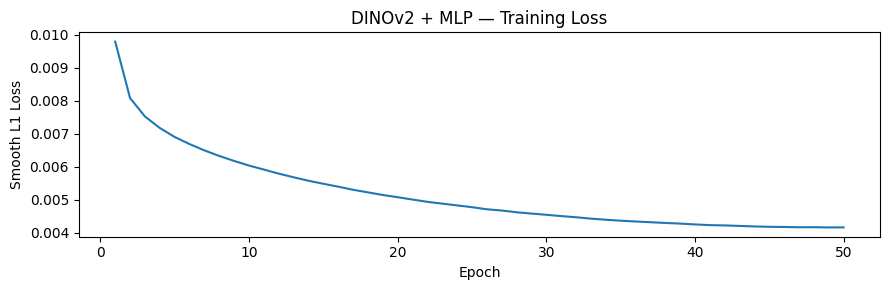

In [55]:
model, history = train_mlp(cfg, train_feats, train_kpts, train_vis)

plt.figure(figsize=(9, 3))
plt.plot(range(1, len(history) + 1), history)
plt.xlabel('Epoch'); plt.ylabel('Smooth L1 Loss')
plt.title('DINOv2 + MLP — Training Loss'); plt.tight_layout(); plt.show()


In [56]:
predictions = predict_coco(model, val_feats, val_meta, cfg)

logger = MetricLogger(cfg.metrics_path)
run_id = f'dinov2_mlp_run_{sum(1 for k in logger.history if "dinov2" in k) + 1}'
metrics = run_coco_eval(cfg, predictions, run_id, logger)


Resumed: 1 experiments in metrics.json
loading annotations into memory...
Done (t=0.31s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.34s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *keypoints*
DONE (t=2.65s).
Accumulating evaluation results...
DONE (t=0.08s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.032
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.134
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.006
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets= 20 ] = 0.045
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets= 20 ] = 0.024
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 20 ] = 0.114
 Average Recall     (AR) @[ IoU=0.50      | area=   all | maxDets= 20 ] = 0.333
 Average Recall     (AR) @[ IoU=0.75      | area=   all | maxDets= 20 ] = 0.059
 Average Recall     (

OKS:   0%|          | 0/2346 [00:00<?, ?it/s]

Logged: dinov2_mlp_run_2


## Ablation Comparison — Approaches A, B, C


In [57]:
logger = MetricLogger(cfg.metrics_path)
logger.get_ablation_table().sort_values('AP_all', ascending=False)

Resumed: 2 experiments in metrics.json


,run_id,model,predictions_file,AP_all,AP_50,AP_75,AP_medium,AP_large,AR_all,AR_50,...,AR_medium,AR_large,batch_size,top_best,top_worst,OKS_mean,OKS_median,OKS_min,OKS_max,OKS_zero_frac
dinov2_mlp_run_2,dinov2_mlp_run_2,dinov2_mlp,/kaggle/working/predictions/dinov2_mlp_run_2_p...,0.032022,0.134354,0.005657,0.044536,0.023580,0.114185,0.333438,...,0.126960,0.097473,128.0,"[{'image_id': 361586, 'category_id': 1, 'keypo...","[{'image_id': 2431, 'category_id': 1, 'keypoin...",0.270443,0.252459,1.230196e-126,0.9645,0.0
dinov2_mlp_run_1,dinov2_mlp_run_1,dinov2_mlp,/kaggle/working/predictions/dinov2_mlp_run_1_p...,0.026420,0.115537,0.003105,0.035247,0.020328,0.101008,0.301795,...,0.112264,0.085990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Visualization


In [58]:
COCO_KPT_SIGMAS = np.array([
    .26, .25, .25, .35, .35, .79, .79, .72, .72, .62, .62, 1.07, 1.07, .87, .87, .89, .89
]) / 10.0

SKELETON = [
    (15, 13), (13, 11), (16, 14), (14, 12), (11, 12),
    (5, 11),  (6, 12),  (5, 6),   (5, 7),   (6, 8),
    (7, 9),   (8, 10),  (1, 2),   (0, 1),   (0, 2),
    (1, 3),   (2, 4),   (3, 5),   (4, 6),
]


def _oks_single(pred: np.ndarray, gt: np.ndarray, bbox: list) -> float:
    area = bbox[2] * bbox[3]
    vis  = gt[:, 2] > 0
    if area == 0 or not vis.any():
        return 0.0
    dx = pred[vis, 0] - gt[vis, 0]
    dy = pred[vis, 1] - gt[vis, 1]
    return float(np.exp(-(dx**2 + dy**2) / (2 * area * COCO_KPT_SIGMAS[vis]**2)).mean())


def best_matching_gt(pred_kpts: np.ndarray, gt_list: list):
    best_oks, best_gt_kpts, best_gt_bbox = 0.0, None, None
    for gt_kpts, gt_bbox in gt_list:
        oks = _oks_single(pred_kpts, gt_kpts, gt_bbox)
        if oks > best_oks:
            best_oks, best_gt_kpts, best_gt_bbox = oks, gt_kpts, gt_bbox
    return best_oks, best_gt_kpts, best_gt_bbox


def add_oks_to_predictions(coco_gt, predictions: list) -> list:
    by_image = {}
    for p in predictions:
        by_image.setdefault(p['image_id'], []).append(p)

    for img_id, preds in tqdm(by_image.items(), desc='OKS', leave=False):
        anns = coco_gt.loadAnns(coco_gt.getAnnIds(imgIds=img_id, iscrowd=False))
        gt_list = [
            (np.array(a['keypoints']).reshape(-1, 3), a['bbox'])
            for a in anns if a.get('num_keypoints', 0) > 0
        ]
        for pred in preds:
            pred_kpts = np.array(pred['keypoints']).reshape(-1, 3)
            best_oks, best_gt_kpts, best_gt_bbox = best_matching_gt(pred_kpts, gt_list)
            pred['oks'] = best_oks
            if best_gt_kpts is not None:
                pred['matched_gt_keypoints'] = best_gt_kpts.flatten().tolist()
                pred['matched_gt_bbox'] = best_gt_bbox
    return predictions


def summarize_oks(predictions: list) -> dict:
    oks_vals = [float(p['oks']) for p in predictions if 'oks' in p]
    if not oks_vals:
        return {
            'OKS_mean': np.nan,
            'OKS_median': np.nan,
            'OKS_min': np.nan,
            'OKS_max': np.nan,
            'OKS_zero_frac': np.nan,
        }

    oks_arr = np.array(oks_vals, dtype=float)
    return {
        'OKS_mean': float(oks_arr.mean()),
        'OKS_median': float(np.median(oks_arr)),
        'OKS_min': float(oks_arr.min()),
        'OKS_max': float(oks_arr.max()),
        'OKS_zero_frac': float((oks_arr == 0.0).mean()),
    }


def visualize_ssl(cfg: Config, predictions: list, val_meta: list,
                  coco_gt: COCO, mode: str = 'random', num_samples: int = 3):
    """
    Visualize DINOv2+MLP predictions (green) with GT keypoints (yellow) side-by-side.
    Computes per-prediction OKS on-the-fly to rank best/worst.

    mode: 'random' | 'best' | 'worst'
    """
    # Attach per-prediction OKS using GT annotations
    scored = []
    for pred, meta in zip(predictions, val_meta):
        ann_ids = coco_gt.getAnnIds(imgIds=meta['image_id'], iscrowd=False)
        anns    = coco_gt.loadAnns(ann_ids)
        gt_list = [(np.array(a['keypoints']).reshape(-1, 3), a['bbox'])
                   for a in anns if a.get('num_keypoints', 0) > 0]

        pred_kpts = np.array(pred['keypoints']).reshape(-1, 3)
        oks = max((_oks_single(pred_kpts, gt, b) for gt, b in gt_list), default=0.0)
        scored.append({**pred, 'oks': oks, 'crop_meta': meta['crop_meta'],
                       'gt_list': gt_list})

    if mode == 'best':
        sample = sorted(scored, key=lambda x: x['oks'], reverse=True)[:num_samples]
    elif mode == 'worst':
        sample = sorted(scored, key=lambda x: x['oks'])[:num_samples]
    else:
        idx    = np.random.choice(len(scored), size=min(num_samples, len(scored)), replace=False)
        sample = [scored[i] for i in idx]

    fig, axes = plt.subplots(1, len(sample), figsize=(6 * len(sample), 6))
    axes = [axes] if len(sample) == 1 else list(axes)

    for ax, s in zip(axes, sample):
        img_id   = s['image_id']
        img_info = coco_gt.loadImgs(img_id)[0]
        img      = cv2.imread(str(cfg.val_images / img_info['file_name']))
        if img is None:
            ax.set_title(f"Missing: {img_id}"); ax.axis('off'); continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        pred_kpts = np.array(s['keypoints']).reshape(-1, 3)

        # Best-matching GT for overlay
        best_gt = None
        if s['gt_list']:
            best_gt = max(s['gt_list'],
                          key=lambda x: _oks_single(pred_kpts, x[0], x[1]))[0]

        # Draw prediction (green skeleton + red dots)
        for u, v in SKELETON:
            ku, kv = pred_kpts[u], pred_kpts[v]
            if ku[2] > 0.1 and kv[2] > 0.1:
                cv2.line(img, (int(ku[0]), int(ku[1])), (int(kv[0]), int(kv[1])), (0, 255, 0), 2)
        for kx, ky, kc in pred_kpts:
            if kc > 0.1:
                cv2.circle(img, (int(kx), int(ky)), 4, (255, 0, 0), -1)

        # Draw GT (yellow skeleton + cyan dots)
        if best_gt is not None:
            for u, v in SKELETON:
                gu, gv = best_gt[u], best_gt[v]
                if gu[2] > 0 and gv[2] > 0:
                    cv2.line(img, (int(gu[0]), int(gu[1])), (int(gv[0]), int(gv[1])), (0, 255, 255), 2)
            for gx, gy, gc in best_gt:
                if gc > 0:
                    cv2.circle(img, (int(gx), int(gy)), 3, (255, 255, 0), -1)

        ax.imshow(img); ax.axis('off')
        ax.set_title(f"img_id={img_id}\nOKS: {s['oks']:.4f}")

    plt.suptitle(f"DINOv2 + MLP  [{mode.upper()}]  "
                 f"green=pred  yellow=GT", fontsize=9, y=1.02)
    plt.tight_layout(); plt.show()


loading annotations into memory...
Done (t=0.28s)
creating index...
index created!


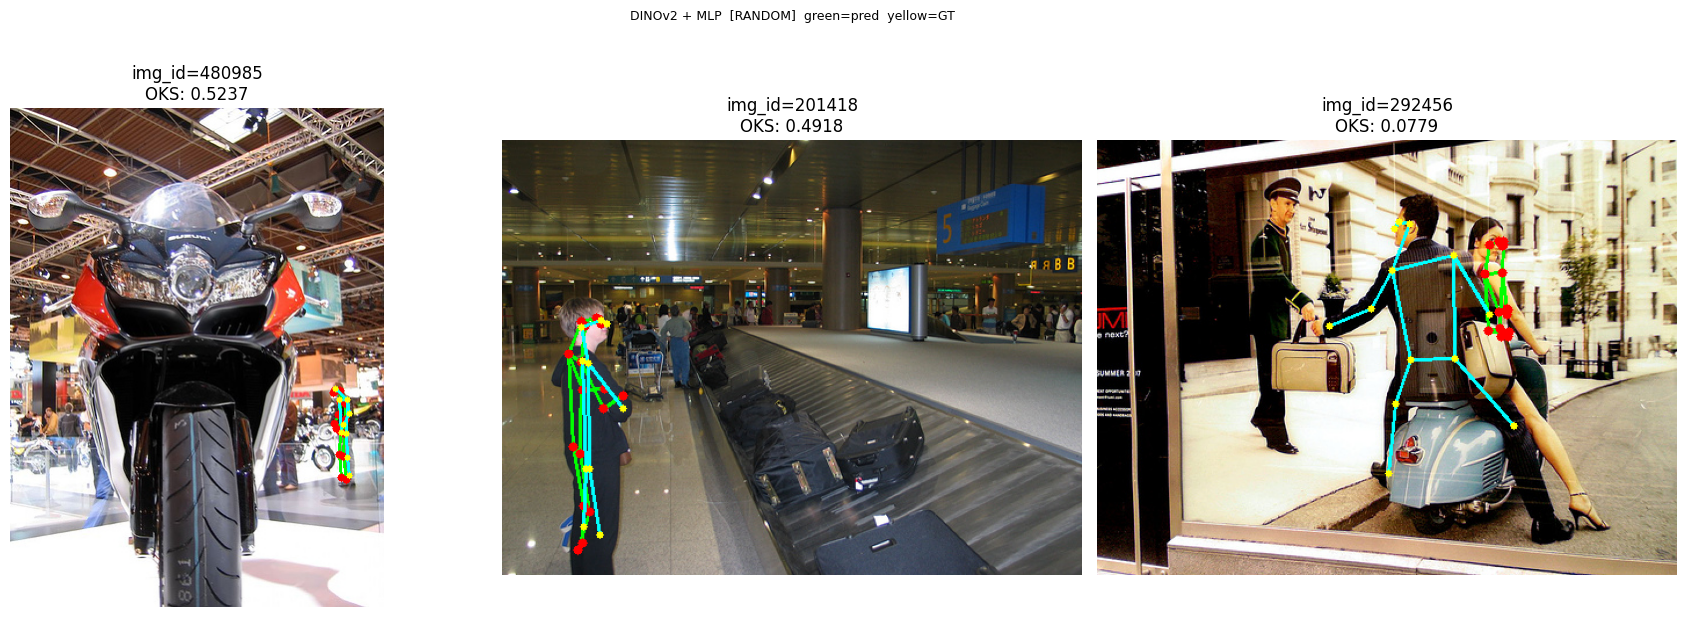

In [59]:
coco_gt_viz = COCO(cfg.val_json)
visualize_ssl(cfg, predictions, val_meta, coco_gt_viz, mode='random', num_samples=3)


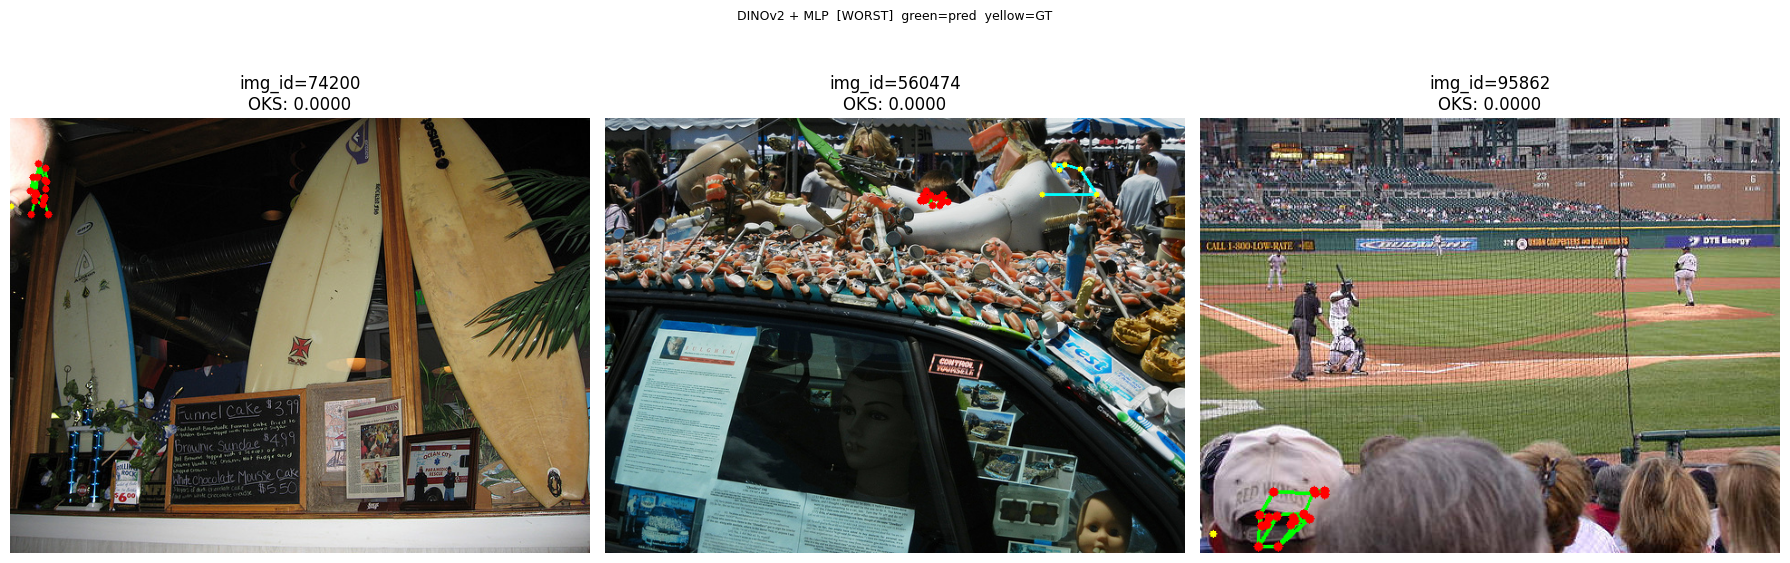

In [60]:
visualize_ssl(cfg, predictions, val_meta, coco_gt_viz, mode='worst', num_samples=3)


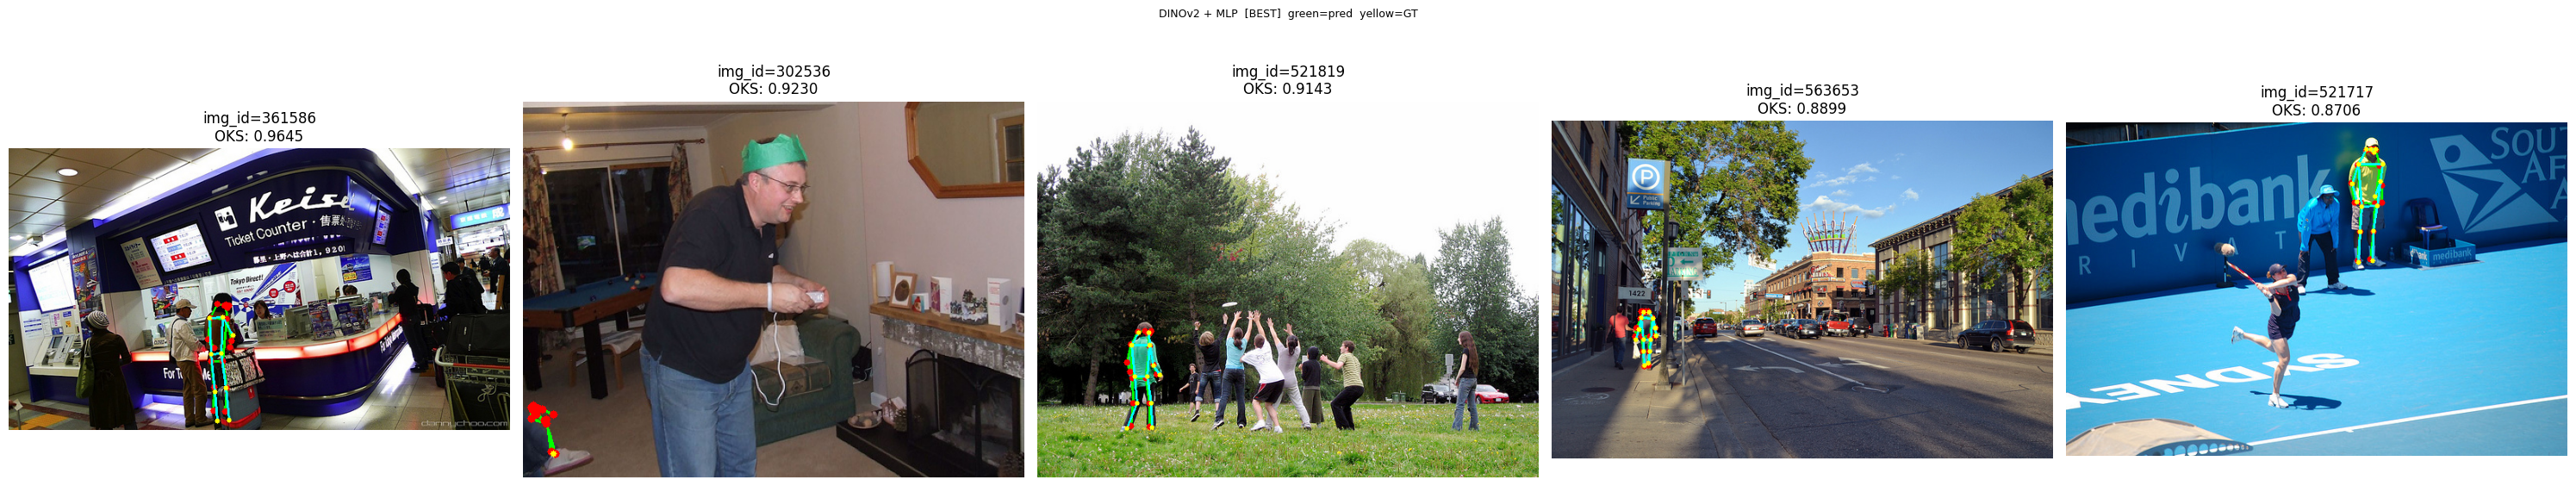

In [61]:
visualize_ssl(cfg, predictions, val_meta, coco_gt_viz, mode='best', num_samples=5)


## Discussion

### When are self-supervised features competitive with pose-specific models?

DINOv2 is trained with a self-distillation objective (DINO) on a large unlabeled image corpus.
Its CLS token encodes a rich global scene representation, but **not explicitly keypoint-localized features**.
Compared to task-specific models like Keypoint R-CNN or YOLO-Pose:

| Aspect | DINOv2 + MLP | Keypoint R-CNN / YOLO |
|---|---|---|
| Backbone pretraining | Self-supervised (no labels) | Supervised on COCO |
| Spatial precision | CLS token — global, no positional grounding | Feature pyramids with spatial resolution |
| Speed | Feature extraction slow; MLP inference fast | End-to-end; optimized for inference |
| Adaptability | Easy to swap backbone; no task-specific arch | Requires reimplementation for new tasks |

**Key limitations of the CLS-token approach:**
- A single global vector has no spatial locality — the MLP must implicitly recover positional information from global context, which is fundamentally harder than the direct spatial regression that FPN-based heads perform.
- Occluded or out-of-frame keypoints receive no special treatment; the model cannot express "I don't see this keypoint."

**When SSL features are competitive:**
- Low-data regimes where task-specific supervision is scarce (fine-tuning a small MLP is cheaper than annotating thousands of keypoints).
- Cross-domain transfer where the target domain is visually different from COCO (DINOv2 has seen more diverse images).
- As a strong baseline for rapidly prototyping new keypoint tasks with minimal engineering effort.

**Improvement directions:**
- Use patch tokens instead of (or in addition to) CLS — patch tokens retain spatial structure and give the MLP positional information.
- Fine-tune the last few DINOv2 layers end-to-end (with a small LR) rather than freezing the backbone completely.
- Add a deconvolutional heatmap head instead of a direct regression MLP, preserving spatial resolution.
